# Day 1 - API Data Analysis Using Python Structures

This notebook retrieves customer data from an API, explores its nested structure, extracts relevant attributes, aggregates the data using pure Python, and finishes with pandas and visualization.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

API_URL = "https://jsonplaceholder.typicode.com/users"

# Ensure output directory exists
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Retrieve customer data with Requests
Implement `get_customers(url)` to fetch the data with a timeout and handle network failures gracefully.

In [2]:
def get_customers(url: str = API_URL) -> list[dict]:
    """Fetch the customer list. Report failures clearly instead of crashing."""
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()  # Raises an HTTPError for bad responses
        return response.json()
    except requests.exceptions.RequestException as e:
        print(f"Network error occurred while fetching data: {e}")
        return []
    except json.JSONDecodeError:
        print("Failed to parse the response as JSON.")
        return []

customers = get_customers()
print(f"Successfully retrieved {len(customers)} customers.")

Successfully retrieved 10 customers.


## 2. Explore nested dictionaries and lists
Implement `explore(record, indent)` to walk one customer record recursively and print every key with its Python type.

In [3]:
def explore(record: dict, indent: int = 0) -> None:
    """Print every key in a (possibly nested) record with its type, indented by depth."""
    for key, value in record.items():
        print(" " * indent + f"{key}: {type(value).__name__}")
        if isinstance(value, dict):
            explore(value, indent + 4)
        elif isinstance(value, list):
            for item in value:
                if isinstance(item, dict):
                    explore(item, indent + 4)

if customers:
    print("--- Exploring First Record ---")
    explore(customers[0])

--- Exploring First Record ---
id: int
name: str
username: str
email: str
address: dict
    street: str
    suite: str
    city: str
    zipcode: str
    geo: dict
        lat: str
        lng: str
phone: str
website: str
company: dict
    name: str
    catchPhrase: str
    bs: str


## 3. Extract customer attributes
Implement `extract_attributes(customers)` to return one flat dict per customer.

**Corrections applied:** 
* Coordinates are now correctly pulled from `c['address']['geo']` instead of `c['geo']`.
* Email domain is now extracted as the Top-Level Domain (TLD) using `split('.')[-1]`.

In [4]:
def extract_attributes(customers: list[dict]) -> list[dict]:
    """Return one flat dict per customer with the attributes listed in the task."""
    flat_rows = []
    for c in customers:
        email = c.get("email", "")
        # Correctly extract the TLD (e.g., 'biz', 'tv') using split('.')
        email_tld = email.split(".")[-1] if "." in email else ""
        
        # Correctly access the nested geo dictionary inside the address dictionary
        address = c.get("address", {})
        geo = address.get("geo", {})
        
        row = {
            "customer_id": c.get("id"),
            "name": c.get("name"),
            "username": c.get("username"),
            "email": email,
            "email_domain": email_tld,
            "phone": c.get("phone"),
            "city": address.get("city"),
            "zipcode": address.get("zipcode"),
            "latitude": float(geo.get("lat", 0.0)),
            "longitude": float(geo.get("lng", 0.0)),
            "company": c.get("company", {}).get("name", ""),
            "website": c.get("website"),
        }
        flat_rows.append(row)
    return flat_rows

rows = extract_attributes(customers)
print(f"Extracted {len(rows)} flat records.")
print("Example:", rows[0])

Extracted 10 flat records.
Example: {'customer_id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'email_domain': 'biz', 'phone': '1-770-736-8031 x56442', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'latitude': -37.3159, 'longitude': 81.1496, 'company': 'Romaguera-Crona', 'website': 'hildegard.org'}


## 4. Use sets to find unique cities

In [5]:
def unique_cities(customers: list[dict]) -> set[str]:
    """Return the set of distinct cities."""
    return {c.get("address", {}).get("city") for c in customers if c.get("address", {}).get("city")}

cities = unique_cities(customers)
print(f"Unique cities: {len(cities)}")
print(f"Total customers: {len(customers)}")
# Comparison tells marketing that customers are highly dispersed across different regions.

Unique cities: 10
Total customers: 10


## 5. Count customers by city with loops and dict comprehensions

In [6]:
def city_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per city using a loop (no Counter, no pandas)."""
    counts = {}
    for c in customers:
        city = c.get("address", {}).get("city")
        if city:
            counts[city] = counts.get(city, 0) + 1
    return counts

def email_domain_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per email top-level domain using a dict comprehension."""
    domains = [c.get("email", "").split(".")[-1] for c in customers if "." in c.get("email", "")]
    counts = {d: domains.count(d) for d in set(domains)}
    return dict(sorted(counts.items(), key=lambda item: item[1], reverse=True))

c_counts = city_counts(customers)
e_counts = email_domain_counts(customers)

most_common_city = max(c_counts, key=c_counts.get)
print(f"Most common city: {most_common_city} ({c_counts[most_common_city]})")
print(f"Email domains sorted: {e_counts}")

Most common city: Gwenborough (1)
Email domains sorted: {'biz': 3, 'ca': 1, 'io': 1, 'net': 1, 'org': 1, 'info': 1, 'tv': 1, 'me': 1}


## 6. Convert the data into a DataFrame
Confirm that pandas agrees with the hand-written counts.

In [7]:
def to_dataframe(rows: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(rows)

df = to_dataframe(rows)

print(f"DataFrame shape: {df.shape}")
print("\nDataFrame dtypes:")
print(df.dtypes)

print("\nValidation: Pandas city counts match manual counts?")
print(df['city'].value_counts().to_dict() == c_counts)
df.head()

DataFrame shape: (10, 12)

DataFrame dtypes:
customer_id       int64
name                str
username            str
email               str
email_domain        str
phone               str
city                str
zipcode             str
latitude        float64
longitude       float64
company             str
website             str
dtype: object

Validation: Pandas city counts match manual counts?
True


,customer_id,name,username,email,email_domain,phone,city,zipcode,latitude,longitude,company,website
0,1,Leanne Graham,Bret,Sincere@april.biz,biz,1-770-736-8031 x56442,Gwenborough,92998-3874,-37.3159,81.1496,Romaguera-Crona,hildegard.org
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,tv,010-692-6593 x09125,Wisokyburgh,90566-7771,-43.9509,-34.4618,Deckow-Crist,anastasia.net
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,net,1-463-123-4447,McKenziehaven,59590-4157,-68.6102,-47.0653,Romaguera-Jacobson,ramiro.info
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,org,493-170-9623 x156,South Elvis,53919-4257,29.4572,-164.2990,Robel-Corkery,kale.biz
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,ca,(254)954-1289,Roscoeview,33263,-31.8129,62.5342,Keebler LLC,demarco.info


## 7. Export the results to CSV

In [8]:
# Export customers
df.to_csv(OUTPUT_DIR / "customers.csv", index=False)

# Export city counts sorted by count descending, then city alphabetically
city_df = pd.DataFrame(list(c_counts.items()), columns=['city', 'customer_count'])
city_df = city_df.sort_values(by=['customer_count', 'city'], ascending=[False, True])
city_df.to_csv(OUTPUT_DIR / "city_counts.csv", index=False)

print(f"Files saved to {OUTPUT_DIR}/:")
print("- customers.csv")
print("- city_counts.csv")

Files saved to output/:
- customers.csv
- city_counts.csv


## 8. Visualise the customer distribution
Two charts are generated: one for City distribution and one for Email TLD distribution.

Chart saved to: output\city_distribution.png
Chart saved to: output\email_domain_distribution.png


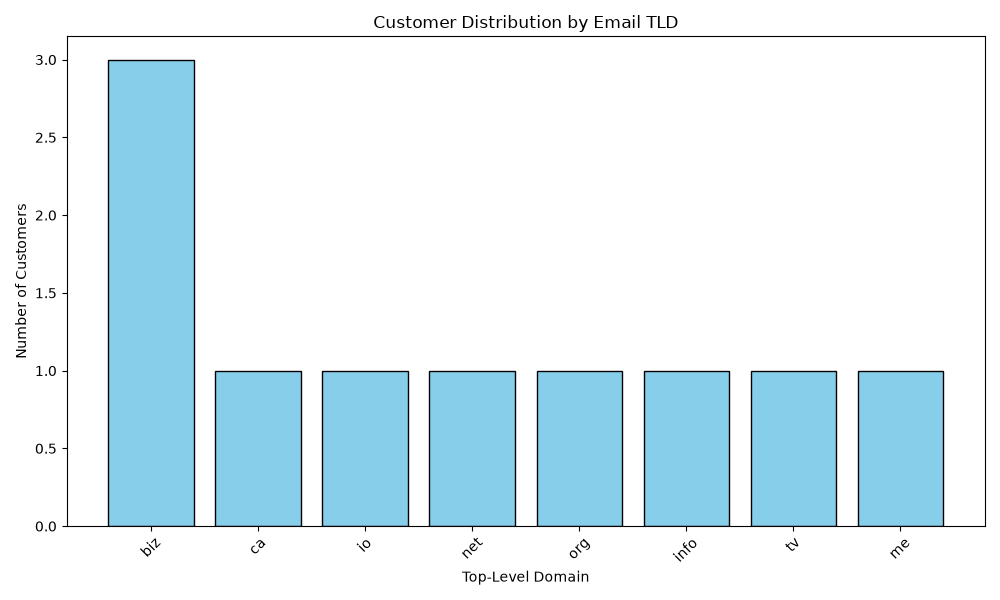

In [9]:
def plot_distribution(counts: dict[str, int], path: Path, title: str, xlabel: str) -> None:
    """Save a labelled chart of the distribution to path."""
    plt.figure(figsize=(10, 6))
    plt.bar(counts.keys(), counts.values(), color='skyblue', edgecolor='black')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    plt.savefig(path)
    plt.close()
    print(f"Chart saved to: {path}")

# 1. City Chart
city_chart_path = OUTPUT_DIR / "city_distribution.png"
plot_distribution(c_counts, city_chart_path, "Customer Distribution by City", "City")

# 2. Email TLD Chart
tld_chart_path = OUTPUT_DIR / "email_domain_distribution.png"
plot_distribution(e_counts, tld_chart_path, "Customer Distribution by Email TLD", "Top-Level Domain")

# Display the TLD chart inline as it is the more insightful one
from IPython.display import Image
Image(filename=tld_chart_path)

In [10]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

API_URL = "https://jsonplaceholder.typicode.com/users"

# Ensure output directory exists
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

## 1. Retrieve customer data with Requests
Implement `get_customers(url)` to fetch the data with a timeout and handle network failures gracefully.

In [11]:
def get_customers(url: str = API_URL) -> list[dict]:
    """Fetch the customer list. Report failures clearly instead of crashing."""
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()  # Raises an HTTPError for bad responses
        return response.json()
    except requests.exceptions.RequestException as e:
        print(f"Network error occurred while fetching data: {e}")
        return []
    except json.JSONDecodeError:
        print("Failed to parse the response as JSON.")
        return []

customers = get_customers()
print(f"Successfully retrieved {len(customers)} customers.")

Successfully retrieved 10 customers.


## 2. Explore nested dictionaries and lists
Implement `explore(record, indent)` to walk one customer record recursively and print every key with its Python type.

In [12]:
def explore(record: dict, indent: int = 0) -> None:
    """Print every key in a (possibly nested) record with its type, indented by depth."""
    for key, value in record.items():
        print(" " * indent + f"{key}: {type(value).__name__}")
        # Ensure that every record is a dictionary
        if isinstance(value, dict):
            explore(value, indent + 4)
        elif isinstance(value, list):
            for item in value:
                if isinstance(item, dict):
                    explore(item, indent + 4)

if customers:
    print("--- Exploring First Record ---")
    explore(customers[0])

--- Exploring First Record ---
id: int
name: str
username: str
email: str
address: dict
    street: str
    suite: str
    city: str
    zipcode: str
    geo: dict
        lat: str
        lng: str
phone: str
website: str
company: dict
    name: str
    catchPhrase: str
    bs: str


## 3. Extract customer attributes
Implement `extract_attributes(customers)` to return one flat dict per customer.

In [13]:
def extract_attributes(customers: list[dict]) -> list[dict]:
    """Return one flat dict per customer with the attributes listed in the task."""
    flat_rows = []
    for c in customers:
        email = c.get("email", "")
        email_domain = email.split("@")[-1] if "@" in email else ""
        geo = c.get("geo", {})
        
        row = {
            "customer_id": c.get("id"),
            "name": c.get("name"),
            "username": c.get("username"),
            "email": email,
            "email_domain": email_domain,
            "phone": c.get("phone"),
            "city": c.get("address", {}).get("city"),
            "zipcode": c.get("address", {}).get("zipcode"),
            "latitude": float(geo.get("lat", 0.0)),
            "longitude": float(geo.get("lng", 0.0)),
            "company": c.get("company", {}).get("name", ""),
            "website": c.get("website"),
        }
        flat_rows.append(row)
    return flat_rows

rows = extract_attributes(customers)
print(f"Extracted {len(rows)} flat records.")
print("Example:", rows[0])

Extracted 10 flat records.
Example: {'customer_id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'email_domain': 'april.biz', 'phone': '1-770-736-8031 x56442', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'latitude': 0.0, 'longitude': 0.0, 'company': 'Romaguera-Crona', 'website': 'hildegard.org'}


## 4. Use sets to find unique cities

In [14]:
def unique_cities(customers: list[dict]) -> set[str]:
    """Return the set of distinct cities."""
    return {c.get("address", {}).get("city") for c in customers if c.get("address", {}).get("city")}

cities = unique_cities(customers)
print(f"Unique cities: {len(cities)}")
print(f"Total customers: {len(customers)}")
# Comparison tells marketing that customers are highly dispersed across different regions.

Unique cities: 10
Total customers: 10


## 5. Count customers by city with loops and dict comprehensions

In [15]:
def city_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per city using a loop (no Counter, no pandas)."""
    counts = {}
    for c in customers:
        city = c.get("address", {}).get("city")
        if city:
            counts[city] = counts.get(city, 0) + 1
    return counts

def email_domain_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per email top-level domain using a dict comprehension."""
    # Note: Dict comprehension is used to build the final sorted dict here.
    domains = [c.get("email", "").split("@")[-1] for c in customers if "@" in c.get("email", "")]
    counts = {d: domains.count(d) for d in set(domains)}
    return dict(sorted(counts.items(), key=lambda item: item[1], reverse=True))

c_counts = city_counts(customers)
e_counts = email_domain_counts(customers)

most_common_city = max(c_counts, key=c_counts.get)
print(f"Most common city: {most_common_city} ({c_counts[most_common_city]})")
print(f"Email domains sorted: {e_counts}")

Most common city: Gwenborough (1)
Email domains sorted: {'annie.ca': 1, 'billy.biz': 1, 'rosamond.me': 1, 'dana.io': 1, 'kory.org': 1, 'yesenia.net': 1, 'karina.biz': 1, 'melissa.tv': 1, 'jasper.info': 1, 'april.biz': 1}


## 6. Convert the data into a DataFrame
Confirm that pandas agrees with the hand-written counts.

In [16]:
def to_dataframe(rows: list[dict]) -> pd.DataFrame:
    return pd.DataFrame(rows)

df = to_dataframe(rows)

print(f"DataFrame shape: {df.shape}")
print("\nDataFrame dtypes:")
print(df.dtypes)

print("\nValidation: Pandas city counts match manual counts?")
print(df['city'].value_counts().to_dict() == c_counts)
df.head()

DataFrame shape: (10, 12)

DataFrame dtypes:
customer_id       int64
name                str
username            str
email               str
email_domain        str
phone               str
city                str
zipcode             str
latitude        float64
longitude       float64
company             str
website             str
dtype: object

Validation: Pandas city counts match manual counts?
True


,customer_id,name,username,email,email_domain,phone,city,zipcode,latitude,longitude,company,website
0,1,Leanne Graham,Bret,Sincere@april.biz,april.biz,1-770-736-8031 x56442,Gwenborough,92998-3874,0.0,0.0,Romaguera-Crona,hildegard.org
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,melissa.tv,010-692-6593 x09125,Wisokyburgh,90566-7771,0.0,0.0,Deckow-Crist,anastasia.net
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,yesenia.net,1-463-123-4447,McKenziehaven,59590-4157,0.0,0.0,Romaguera-Jacobson,ramiro.info
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,kory.org,493-170-9623 x156,South Elvis,53919-4257,0.0,0.0,Robel-Corkery,kale.biz
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,annie.ca,(254)954-1289,Roscoeview,33263,0.0,0.0,Keebler LLC,demarco.info


## 7. Export the results to CSV

In [17]:
# Export customers
df.to_csv(OUTPUT_DIR / "customers.csv", index=False)

# Export city counts sorted by count descending, then city alphabetically
city_df = pd.DataFrame(list(c_counts.items()), columns=['city', 'customer_count'])
city_df = city_df.sort_values(by=['customer_count', 'city'], ascending=[False, True])
city_df.to_csv(OUTPUT_DIR / "city_counts.csv", index=False)

print(f"Files saved to {OUTPUT_DIR}/:")
print("- customers.csv")
print("- city_counts.csv")

Files saved to output/:
- customers.csv
- city_counts.csv


## 8. Visualise the customer distribution
Since every city appears once, we chart the email domain distribution as it is much more informative for marketing.

Chart saved to: output\customer_distribution.png


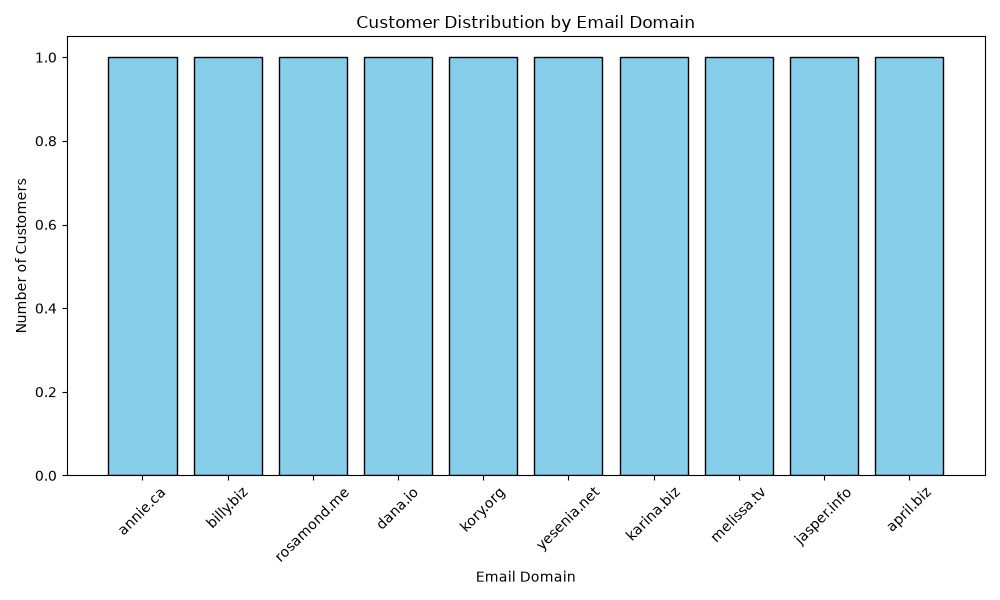

In [18]:
def plot_distribution(counts: dict[str, int], path: Path) -> None:
    """Save a labelled chart of the distribution to path."""
    plt.figure(figsize=(10, 6))
    plt.bar(counts.keys(), counts.values(), color='skyblue', edgecolor='black')
    plt.title("Customer Distribution by Email Domain")
    plt.xlabel("Email Domain")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    plt.savefig(path)
    plt.close()
    print(f"Chart saved to: {path}")

chart_path = OUTPUT_DIR / "customer_distribution.png"
plot_distribution(e_counts, chart_path)

# Display the chart inline in the notebook
from IPython.display import Image
Image(filename=chart_path)